#**Assignment 3 --------------------**

In [8]:
# load the data
import random
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

local_path = Path("data/diabetes.csv")
data_url = 'https://app.box.com/s/7qv44umhw0vnzgmoe9krfkfkv5kf2atv'

source = local_path if local_path.exists() else data_url
df_raw = pd.read_csv(source)

print(f'Loaded {df_raw.shape[0]} rows and {df_raw.shape[1]} columns from {source}')

Loaded 768 rows and 9 columns from data/diabetes.csv


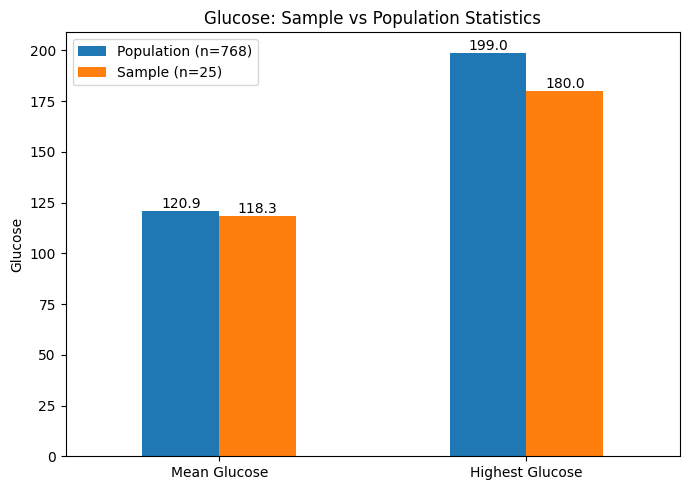

In [9]:
# Part a

# Take random sample
sample_df = df_raw.sample(n=25, random_state=1)

# Find mean and highest glucose values
pop_mean = df_raw['Glucose'].mean()
pop_max = df_raw['Glucose'].max()
samp_mean = sample_df['Glucose'].mean()
samp_max = sample_df['Glucose'].max()

# Compare
comparison = pd.DataFrame({
    'Population (n=768)': [pop_mean, pop_max],
    'Sample (n=25)': [samp_mean, samp_max]
}, index=['Mean Glucose', 'Highest Glucose'])

# Chart
ax = comparison.plot(kind='bar', rot=0, figsize=(7, 5))
ax.set_title('Glucose: Sample vs Population Statistics')
ax.set_ylabel('Glucose')
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f')
plt.tight_layout()

plt.savefig('charts/glucose_sample_vs_population_stats.png')
plt.show()

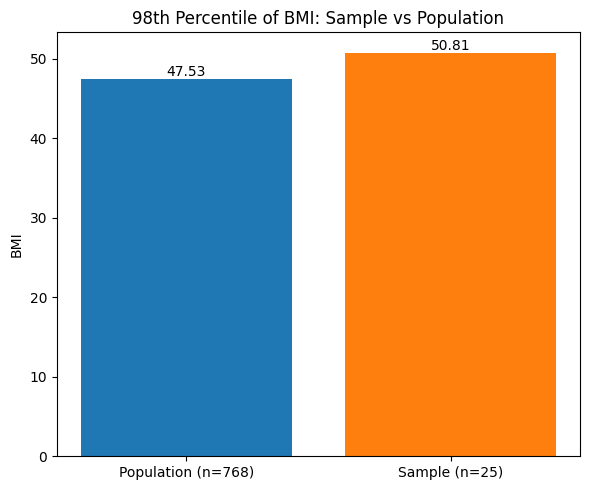

In [10]:
# Part b

# Population
pop_p98 = df_raw['BMI'].quantile(0.98)

# Sample
samp_p98 = sample_df['BMI'].quantile(0.98)

# Comparison
plt.figure(figsize=(6, 5))
bars = plt.bar(['Population (n=768)', 'Sample (n=25)'], [pop_p98, samp_p98],
               color=['C0', 'C1'])
plt.bar_label(bars, fmt='%.2f')
plt.title('98th Percentile of BMI: Sample vs Population')
plt.ylabel('BMI')
plt.tight_layout()

plt.savefig('charts/sample_vs_population_98th_percentile_bmi.png')
plt.show()

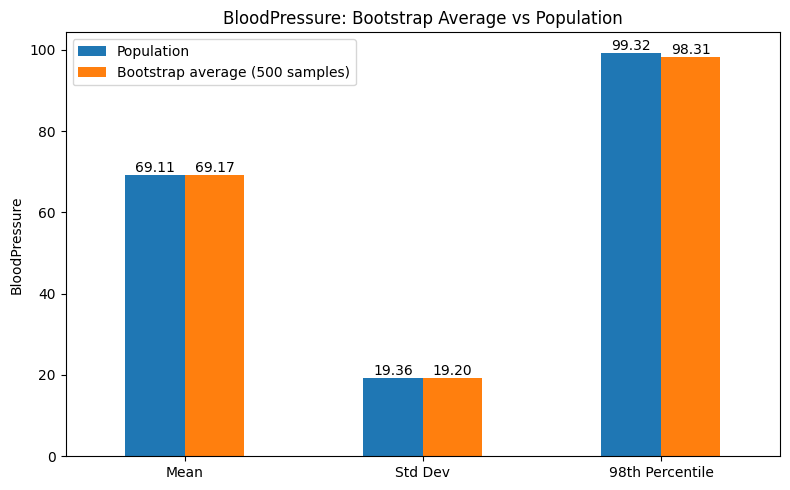

In [11]:
# Part c
n_boot = 500
n_size = 150
pctl = 0.98 # just using the percentile from part b

boot_means, boot_stds, boot_pctls = [], [], []
for i in range(n_boot):
    s = df_raw['BloodPressure'].sample(n=n_size, replace=True, random_state=i)
    boot_means.append(s.mean())
    boot_stds.append(s.std())
    boot_pctls.append(s.quantile(pctl))

boot_avg = [np.mean(boot_means), np.mean(boot_stds), np.mean(boot_pctls)]
pop_stats = [df_raw['BloodPressure'].mean(),
             df_raw['BloodPressure'].std(),
             df_raw['BloodPressure'].quantile(pctl)]

labels = ['Mean', 'Std Dev', f'{int(pctl*100)}th Percentile']
comparison = pd.DataFrame({'Population': pop_stats,
                           'Bootstrap average (500 samples)': boot_avg},
                          index=labels)

ax = comparison.plot(kind='bar', rot=0, figsize=(8, 5))
ax.set_title('BloodPressure: Bootstrap Average vs Population')
ax.set_ylabel('BloodPressure')
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f')
plt.tight_layout()

plt.savefig('charts/bloodpressure_sample_vs_population_stats.png')
plt.show()

# **Report:**
I treated the 768 patients as the population and drew 500 bootstrap samples of BloodPressure. The bootstrap averages for the mean (69.17) and standard deviation (19.20) are very close to the population's values (69.11 and 19.36), which confirms that both mean and standard deviation are reliable statistics.
The 98th percentile, on the other hand, differs more (bootstrap 98.31 vs population 99.32). In class, we discussed how the 98th percentile isn't a reliable statistic for smaller samples, where it is more likely to vary.